# 08 — Benchmark of the traditional methods

Notebooks 04-07 tried the **4 descriptors of the course** (HOG, LBP, colour histograms, SIFT) with the **3 classifiers** (KNN, SVM, Random Forest): 12 methods, all tested in exactly the same way (same crops, same 5 groups of videos, same video decision).

This notebook puts them side by side to answer:
1. Which method is the best **for each frame** (posture) and **for each video** (fall or no fall)?
2. Why are these two rankings different?
3. Which videos are hard for **all** of them?
4. Does **combining** the descriptors help?
5. How does the best traditional method compare with the depth baseline (02) and the skeleton state machine (10)?

Nothing is trained again here: we only read the scores and predictions saved by notebooks 04-07.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROC = Path("..") / "data" / "processed"
DESCRIPTORS = {"HOG": "hog", "LBP": "lbp", "Colour (HSV)": "colour", "SIFT (dense, BoVW)": "sift"}
CLASSIFIERS = ["KNN", "SVM", "RF"]
COLOURS = {"HOG": "#2a78d6", "LBP": "#eb6834", "Colour (HSV)": "#1baf7a", "SIFT (dense, BoVW)": "#eda100"}   # one fixed colour per descriptor

scores = pd.read_csv(PROC / "results_traditional.csv")
preds = {d: pd.read_csv(PROC / f"predictions_{short}.csv") for d, short in DESCRIPTORS.items()}
frames = preds["HOG"][["video", "frame", "frame_label"]]
assert all(p[["video", "frame"]].equals(frames[["video", "frame"]]) for p in preds.values())   # same frames, same order
y = frames.frame_label.to_numpy()
print(f"{len(scores)} methods, {len(frames):,} frames, {frames.video.nunique()} videos")

12 methods, 11,027 frames, 70 videos


💡 **Interpretation:** the **12 methods** (4 descriptors × 3 classifiers) and their predictions for the same **11,027 frames** of the **70 videos**, so they can be compared frame by frame and video by video.

## Step 1 — All 12 methods in one table

Sorted by **video accuracy**, because the goal of the project is the video answer: *fall or no fall*.
Two simple references: always answering *not lying* gives a frame accuracy of 0.640; always answering *no fall* gives a video accuracy of 40 / 70 = 0.571.

In [2]:
scores.sort_values(["video accuracy", "macro F1"], ascending=False).reset_index(drop=True)

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,HOG,KNN,0.859,0.799,0.857,0.833,0.833
1,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
2,HOG,RF,0.855,0.770,0.829,0.767,0.821
3,Colour (HSV),RF,0.896,0.842,0.800,0.767,0.767
4,Colour (HSV),KNN,0.883,0.834,0.800,0.767,0.767
5,HOG,SVM,0.859,0.795,0.800,0.733,0.786
6,LBP,RF,0.866,0.796,0.786,0.733,0.759
7,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
8,LBP,KNN,0.867,0.816,0.771,0.767,0.719
9,LBP,SVM,0.873,0.810,0.757,0.733,0.710


💡 **Interpretation:** all 12 methods beat the simple references (0.640 on frames, 0.571 on videos). The best on videos is **HOG + KNN (0.857)**, then colour + SVM (0.843) and HOG + RF (0.829);
the worst is dense SIFT + SVM (0.743). From best to worst there are only 8 videos of difference.

## Step 2 — Descriptor or classifier: what matters more?

Each square is one method: rows are descriptors, columns are classifiers. Left: the frame score (macro F1); right: the video score.

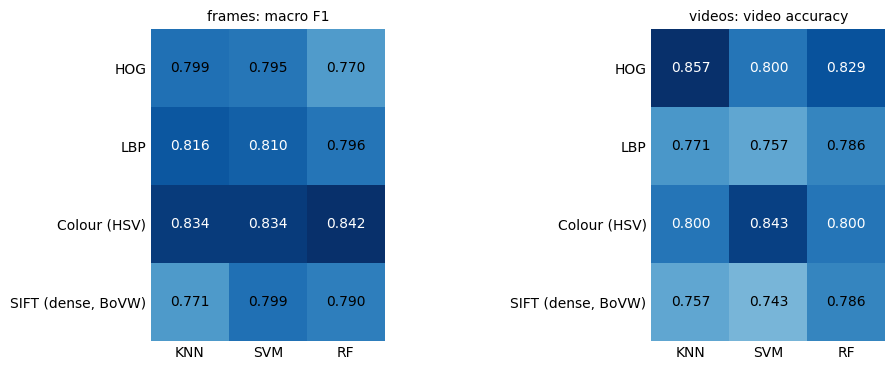

macro F1: gap between the best and worst descriptor (on average) 0.050, between the best and worst classifier 0.010
video accuracy: gap between the best and worst descriptor (on average) 0.067, between the best and worst classifier 0.015


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, column in zip(axes, ["macro F1", "video accuracy"]):
    grid = scores.pivot(index="descriptor", columns="classifier", values=column).loc[list(DESCRIPTORS), CLASSIFIERS]
    ax.imshow(grid, cmap="Blues", vmin=grid.values.min() - 0.1, vmax=grid.values.max())
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            ax.text(c, r, f"{grid.iloc[r, c]:.3f}", ha="center", va="center", fontsize=10,
                    color="white" if grid.iloc[r, c] > grid.values.mean() else "black")
    ax.set_xticks(range(3), CLASSIFIERS); ax.set_yticks(range(4), grid.index)
    ax.set_title(f"{'frames' if column == 'macro F1' else 'videos'}: {column}", fontsize=10)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
plt.tight_layout(); plt.show()

for column in ["macro F1", "video accuracy"]:
    spread = {group: scores.groupby(group)[column].mean().agg(lambda s: s.max() - s.min()) for group in ["descriptor", "classifier"]}
    print(f"{column}: gap between the best and worst descriptor (on average) {spread['descriptor']:.3f}, "
          f"between the best and worst classifier {spread['classifier']:.3f}")

💡 **Interpretation:** the **descriptor matters much more than the classifier**: changing the descriptor moves the score by 0.050 (frames) and 0.067 (videos) on average, changing the classifier only by 0.010 and 0.015.
Colour is the best row on frames; on videos, the two best squares are HOG + KNN and colour + SVM.

## Step 3 — Is the best on frames also the best on videos?

Each dot is one method: horizontally its **frame** score (macro F1), vertically its **video** score.
We also measure, for each method, the **gap** in the share of frames predicted *falling* between fall videos and ADL videos (each video counts once, as in the video decision): the bigger the gap, the easier the video decision should be.

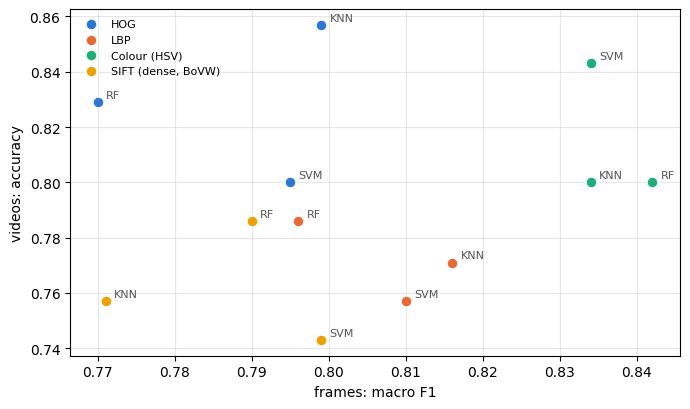

correlation with video accuracy:  frame macro F1 0.16 | falling share gap 0.4


In [4]:
rows = []
for d in DESCRIPTORS:
    for c in CLASSIFIERS:
        falling_share = (preds[d][c] == 0).groupby(frames.video).mean()
        is_fall_video = falling_share.index.str.startswith("fall")
        rows.append({"descriptor": d, "classifier": c,
                     "falling share gap": falling_share[is_fall_video].mean() - falling_share[~is_fall_video].mean()})
check = scores.merge(pd.DataFrame(rows), on=["descriptor", "classifier"])

fig, ax = plt.subplots(figsize=(7, 4.2))
for d in DESCRIPTORS:
    part = check[check.descriptor == d]
    ax.scatter(part["macro F1"], part["video accuracy"], s=70, color=COLOURS[d], label=d, edgecolor="white", linewidth=1.5, zorder=3)
    for _, r in part.iterrows():
        ax.annotate(r["classifier"], (r["macro F1"], r["video accuracy"]), textcoords="offset points", xytext=(6, 3), fontsize=8, color="#555")
ax.set_xlabel("frames: macro F1"); ax.set_ylabel("videos: accuracy")
ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()
print("correlation with video accuracy:  frame macro F1", round(check["macro F1"].corr(check["video accuracy"]), 2),
      "| falling share gap", round(check["falling share gap"].corr(check["video accuracy"]), 2))

💡 **Interpretation:** **almost no link** between the two scores (correlation 0.16): colour + RF is the best on frames but only 0.800 on videos, while HOG + KNN is average on frames but the best on videos.
The *falling* share gap explains a bit more (0.40): the video answer depends on a few borderline videos, so differences of 2-3 videos should not be over-read.

## Step 4 — Video by video: which videos are hard for everyone?

For each descriptor we take its **best classifier for videos** and redo the video decision of notebooks 04-07 (same code), to know which videos it gets wrong.

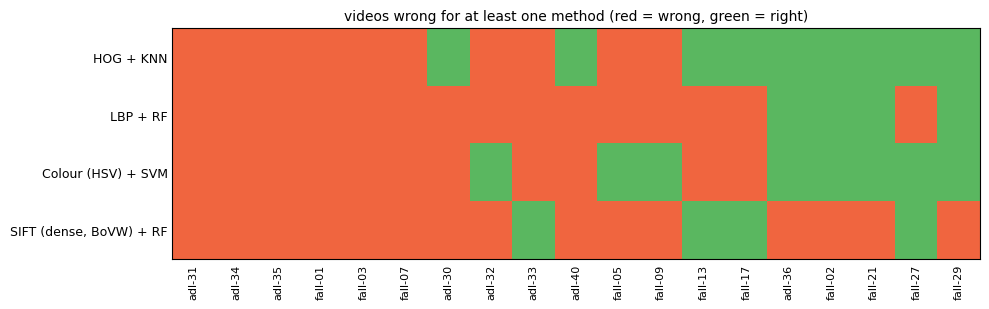

19 of 70 videos are wrong for at least one method; wrong for all 4: ['adl-31', 'adl-34', 'adl-35', 'fall-01', 'fall-03', 'fall-07']


In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

def video_decision(frame_pred):   # same function as notebooks 04-07
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

best_of = (scores.sort_values(["video accuracy", "macro F1"], ascending=False).groupby("descriptor", sort=False).head(1)
           .set_index("descriptor").classifier.loc[list(DESCRIPTORS)])
correct = {}
for d, c in best_of.items():
    share, y_video, video_pred = video_decision(preds[d][c].to_numpy())
    correct[f"{d} + {c}"] = pd.Series(video_pred == y_video, index=share.index)
correct = pd.DataFrame(correct)
hard = correct[~correct.all(axis=1)]
hard = hard.loc[hard.sum(axis=1).sort_values(kind="stable").index]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(hard.T.astype(int), cmap="RdYlGn", vmin=-0.3, vmax=1.3, aspect="auto")
ax.set_xticks(range(len(hard)), hard.index, rotation=90, fontsize=8); ax.set_yticks(range(4), hard.columns, fontsize=9)
ax.set_title("videos wrong for at least one method (red = wrong, green = right)", fontsize=10); ax.tick_params(length=0)
plt.tight_layout(); plt.show()
print(f"{len(hard)} of 70 videos are wrong for at least one method; wrong for all 4: {list(hard.index[hard.sum(axis=1) == 0])}")

💡 **Interpretation:** **51 of 70 videos** are right for all 4 methods. **6 are wrong for all**: `adl-31`, `adl-34`, `adl-35` (people lying down on the floor on purpose) and `fall-01`, `fall-03`, `fall-07` (long fall videos).
These are the limits of a *posture per frame* approach, not of one descriptor.

## Step 5 — Does combining the descriptors help? (majority vote)

Each descriptor sees something different (shape, texture, colour, local patterns). A simple way to combine them: for every frame, the **4 best methods vote** and the posture with the most votes wins.
If there is a tie, we follow HOG, the best method on videos. No new training is needed: the 4 predictions already come from the same video-level tests.

In [6]:
votes = np.stack([preds[d][c].to_numpy() for d, c in best_of.items()], axis=1)
vote = []
for row in votes:
    values, counts = np.unique(row, return_counts=True)
    winners = values[counts == counts.max()]
    vote.append(winners[0] if len(winners) == 1 else row[0])   # tie -> follow HOG (first column)
vote = np.array(vote)

share, y_video, video_pred = video_decision(vote)
vote_scores = {"descriptor": "Vote of the 4", "classifier": "-", "frame accuracy": accuracy_score(y, vote),
               "macro F1": f1_score(y, vote, average="macro"), "video accuracy": accuracy_score(y_video, video_pred),
               "recall (falls)": recall_score(y_video, video_pred), "precision (falls)": precision_score(y_video, video_pred)}
pd.concat([scores.merge(best_of.rename("classifier").reset_index(), on=["descriptor", "classifier"]),
           pd.DataFrame([vote_scores])], ignore_index=True).round(3)

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,LBP,RF,0.866,0.796,0.786,0.733,0.759
1,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
2,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
3,HOG,KNN,0.859,0.799,0.857,0.833,0.833
4,Vote of the 4,-,0.906,0.859,0.814,0.800,0.774


💡 **Interpretation:** the vote gives the **best frames of all** (accuracy 0.906, macro F1 0.859), but only **0.814 on videos** (57/70), below HOG + KNN alone (0.857).
Again: better postures ≠ better video answer, and the vote cannot fix the 6 videos that all 4 methods get wrong.

## Step 6 — The best traditional method against the other approaches

The references come from the earlier notebooks, which used the **same 70 videos and the same 5 video groups**:
- **02**: depth baseline (lowest point of the person in the depth image);
- **10**: state machine on MediaPipe skeletons (speed + angle + height over time, no learning).

Note: with 70 videos, **one video = 1.4 points** of accuracy, so differences of 1-2 points are only 1 video.

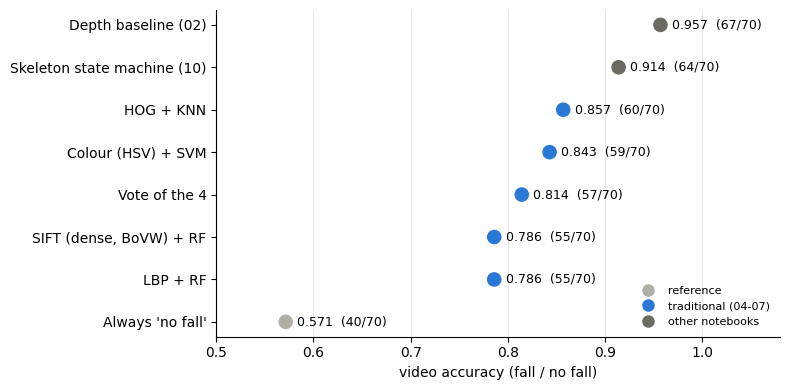

In [7]:
ranking = pd.DataFrame([
    {"method": "Always 'no fall'", "family": "reference", "video accuracy": 40 / 70},
    *[{"method": f"{d} + {c}", "family": "traditional (04-07)",
       "video accuracy": scores.set_index(["descriptor", "classifier"]).loc[(d, c), "video accuracy"]} for d, c in best_of.items()],
    {"method": "Vote of the 4", "family": "traditional (04-07)", "video accuracy": vote_scores["video accuracy"]},
    {"method": "Skeleton state machine (10)", "family": "other notebooks", "video accuracy": 0.914},   # notebook 10
    {"method": "Depth baseline (02)", "family": "other notebooks", "video accuracy": 0.957},          # notebook 02
]).sort_values("video accuracy")
family_colour = {"reference": "#b0aea5", "traditional (04-07)": "#2a78d6", "other notebooks": "#6b6a63"}

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(ranking["video accuracy"], ranking.method, s=90, color=ranking.family.map(family_colour), zorder=3)   # dots, not bars:
for k, value in enumerate(ranking["video accuracy"]):                                                            # the axis does not start at 0
    ax.text(value + 0.012, k, f"{value:.3f}  ({round(value * 70)}/70)", va="center", fontsize=9)
ax.set_xlim(0.5, 1.08); ax.set_xlabel("video accuracy (fall / no fall)"); ax.grid(axis="x", alpha=0.3)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=c) for c in family_colour.values()], labels=list(family_colour),
          fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the best traditional method, **HOG + KNN, gets 60 of 70 videos right**: 4 fewer than the skeleton state machine (64) and 7 fewer than the depth baseline (67).
Both of those use **time** (how the person moves), which the per-frame traditional methods do not see.

## Conclusion of the traditional part

1. **Choice of the best traditional method: HOG + KNN.** It is the best on videos (0.857, 25/30 falls caught, 0.833 precision), very fast (4 s), and it describes the **person's shape**.
   Colour + SVM is only 1 video behind, but step 4 of notebook 06 showed that colour mostly uses the **background** (floor vs wall), a shortcut that would not work in a new room.
2. **The descriptor matters more than the classifier** (gaps of 0.05-0.07 vs 0.01-0.015).
3. **A better frame score does not give a better video answer** (correlation 0.16). Combining the 4 descriptors by vote gives the best frames (0.906) but not the best videos (0.814).
4. **Shared limits:** the same 6 videos are wrong for every method: people who **lie down on purpose** look like fallen people on a single frame, and in **long fall videos** the fall is a small share of the frames.
   Solving this needs **time**: the speed of the movement, the order of the postures. That is why the state machine (0.914) and the depth baseline (0.957) are still ahead.
5. **For the report:** with 70 videos, one video = 1.4 points, so small differences between methods are not meaningful; we look at which videos change, not only at the score.

**Next (part B, notebooks 09-13):** deep learning. Notebook 09 already extracted the **skeletons**; notebook 11 trains **CNNs** (MobileNet, ResNet…) on the same person crops and the same video groups, so the comparison with this benchmark is fair.